In [2]:
!pip install seaborn

In [3]:
import matplotlib.pyplot as plt

import seaborn as sns

# seaborn안에 내장(load) 되어있는 dataset중에서 tips를 가져오라는 의미
tips = sns.load_dataset("tips")
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


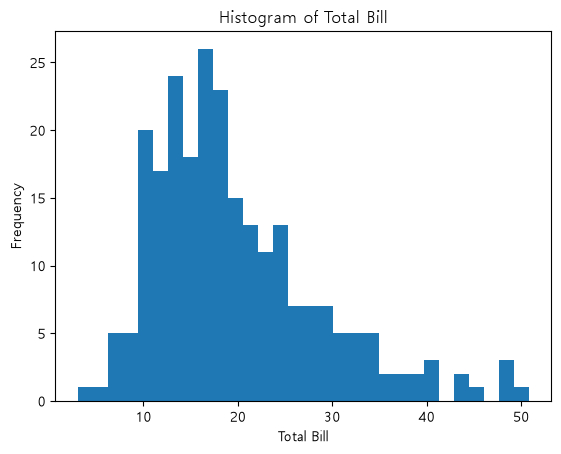

In [20]:
fig = plt.figure() # figure를 가져온다
axes1 = fig.add_subplot(1, 1, 1) # 1행 1열에 하나를 넣는다
axes1.hist(tips['total_bill'], bins=30) 
axes1.set_title('Histogram of Total Bill')
axes1.set_xlabel('Total Bill')
axes1.set_ylabel('Frequency')

plt.show()


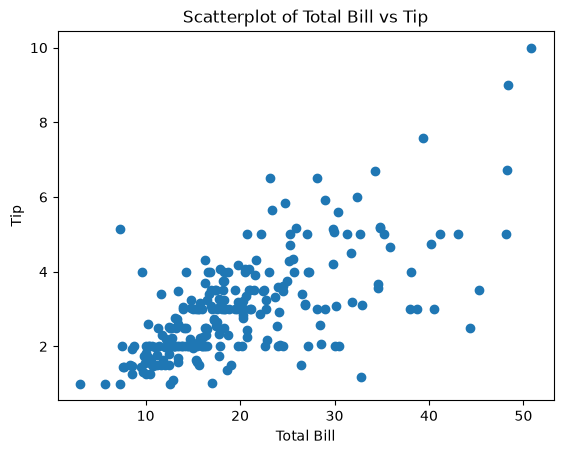

In [12]:
# 산점도 그래프 그리기
scatter_plot = plt.figure()
axes1 = scatter_plot.add_subplot(1, 1, 1)
axes1.scatter(tips['total_bill'], tips['tip'])
axes1.set_title("Scatterplot of Total Bill vs Tip")
axes1.set_xlabel('Total Bill')
axes1.set_ylabel('Tip')
plt.show()

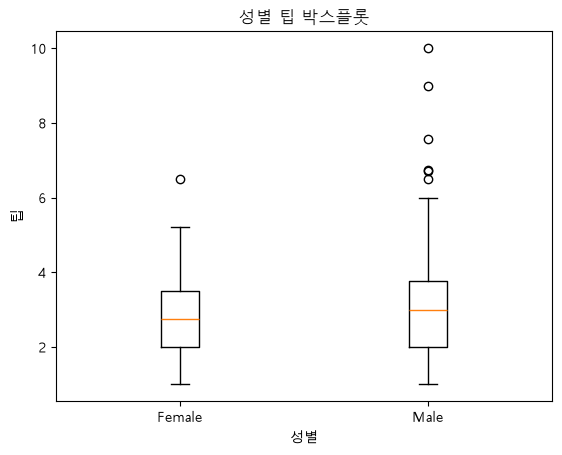

In [18]:
# 박스 플롯 그리기 (이산형 변수와 연속형 변수를 조합해 데이터 분포/이상치 확인)
# 한글 사용
plt.rc('font', family='Malgun Gothic')

box_fig = plt.figure()
axes1 = box_fig.add_subplot(1, 1, 1)
axes1.boxplot([tips[tips['sex'] == 'Female']['tip'], 
                tips[tips['sex']== 'Male']['tip']],
                tick_labels=['Female', 'Male'])
axes1.set_title('성별 팁 박스플롯')
axes1.set_xlabel('성별')
axes1.set_ylabel('팁')
plt.show()

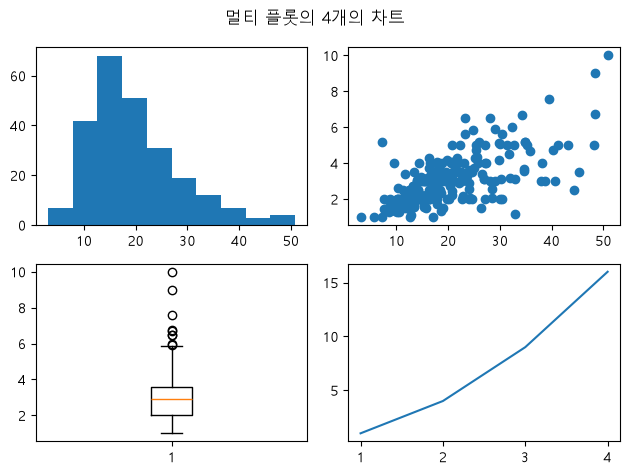

In [22]:
# 2행 2열 구조의 하위 격자 그래프
fig, axes = plt.subplots(nrows=2, ncols=2)

axes[0, 0].hist(tips['total_bill'])
axes[0, 1].scatter(tips['total_bill'], tips['tip'])
axes[1, 0].boxplot(tips['tip'])
axes[1, 1].plot([1, 2, 3, 4], [1, 4, 9, 16])

fig.suptitle("멀티 플롯의 4개의 차트") # 전체 타이틀, super title
fig.tight_layout()
plt.show()


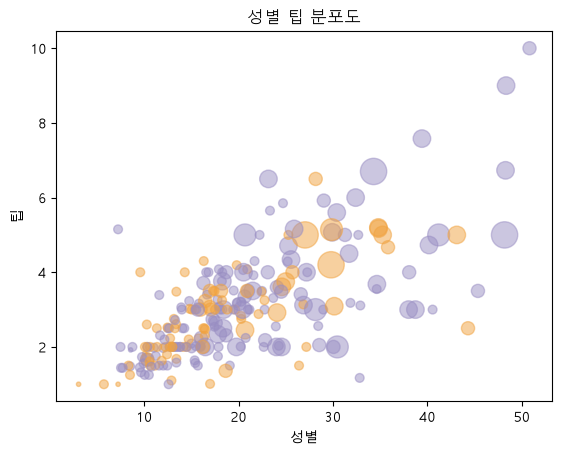

In [23]:
# 변수가 여러개인 그래프
colors = {"Female": "#f1a340", "Male": "#998ec3"}
scatter_plot = plt.figure()
axes1 = scatter_plot.add_subplot(1, 1, 1)

axes1.scatter(data=tips,
              x= 'total_bill',
              y='tip',
              s=tips['size']**2*10,       # s는 점의 크기
              c=tips['sex'].map(colors),  # c는 색상
              alpha=0.5)                  # alpha는 불투명도

axes1.set_xlabel('성별')
axes1.set_ylabel('팁')
axes1.set_title('성별 팁 분포도')

plt.show()

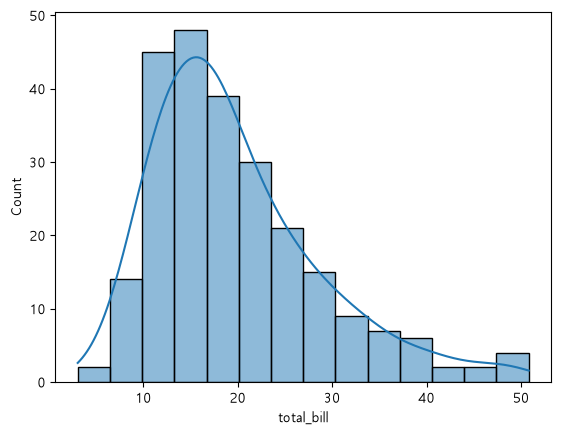

In [24]:
# seaborn 
# 단변량, 변수1개인 그래프 그리기
ax = sns.histplot(tips['total_bill'], kde=True)  # kde는 밀도 표시
plt.show()

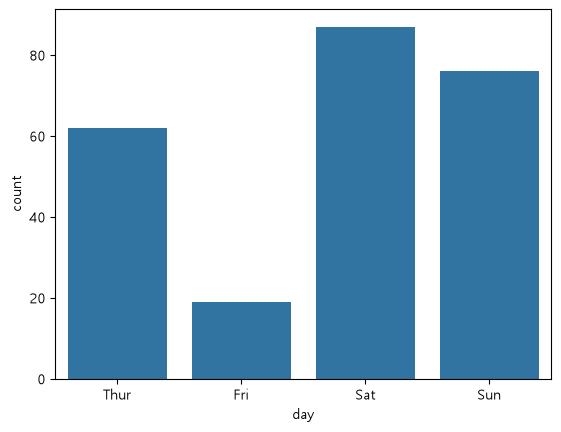

In [25]:
# 요일별 빈도수 세기
ax = sns.countplot(x='day', data=tips)
plt.show()

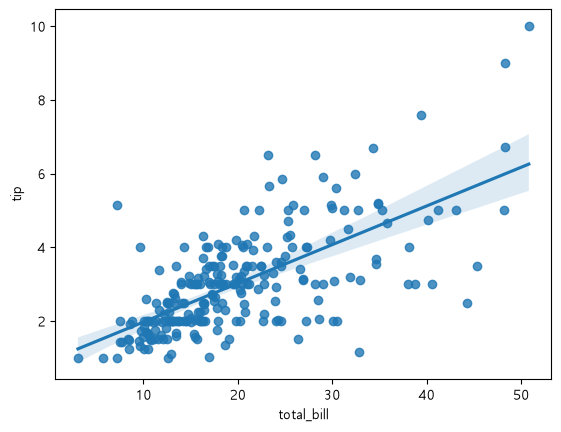

In [26]:
# 다변량, 2개 이상의 변수 그래프 그리기 및 색상 활용
# 1. 회귀선이 포함된 산점도
ax = sns.regplot(x='total_bill', y='tip', data=tips)
plt.show()


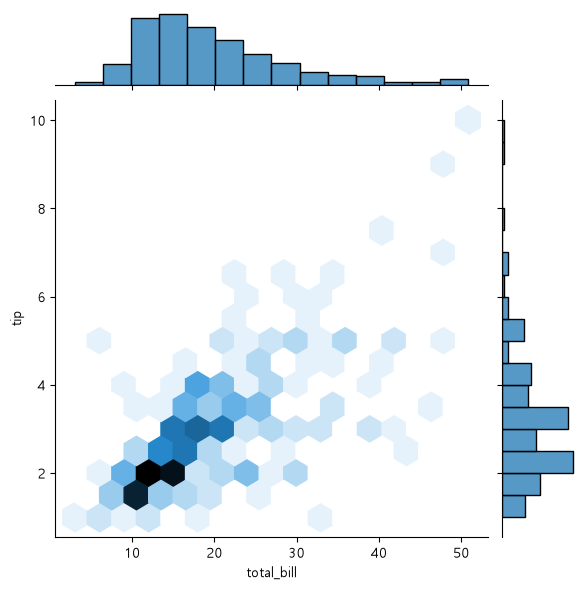

In [ ]:
# 2. 산점도와 히스토그램의 결합
# joint = sns.jointplot(x='total_bill', y='tip', data=tips, kind='scatter') 
joint = sns.jointplot(x='total_bill', y='tip', data=tips, kind='hex') # 육각형
plt.show()

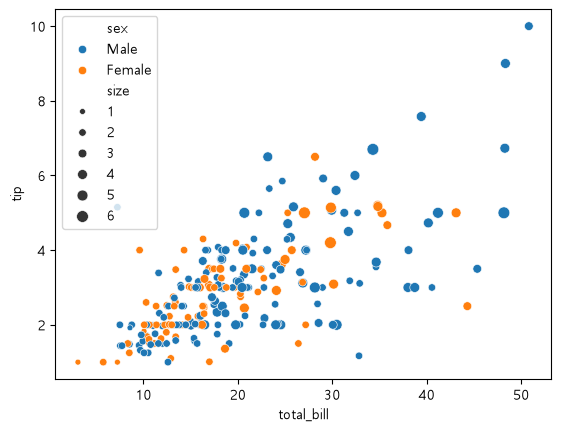

In [29]:
# 3. 범주형 색상 대조(hue)를 적용한 산점도
ax = sns.scatterplot(x='total_bill', y="tip", hue='sex', size="size", data=tips)
plt.show()


3차원/4차원 이상의 복합 그래프 구조

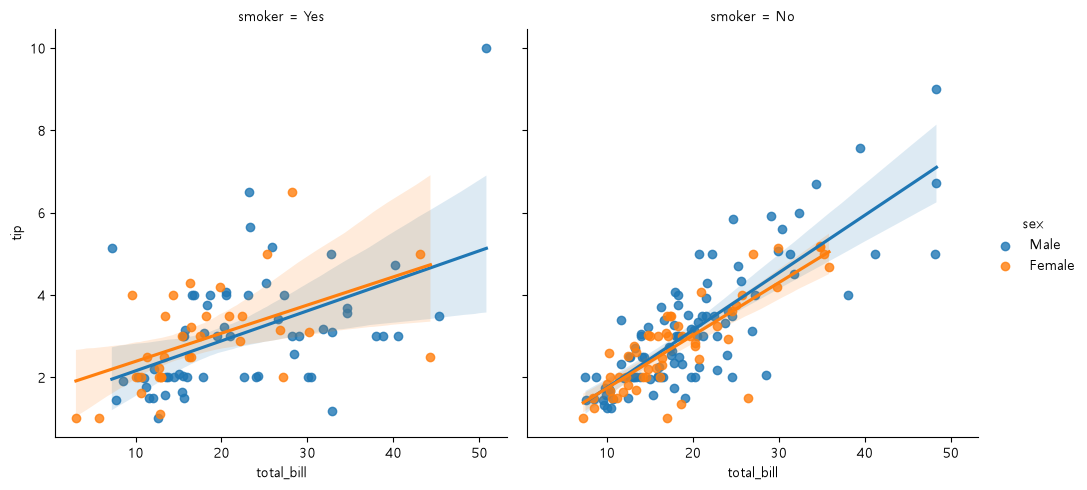

In [31]:
# 성별로 색상이 다르고, 흡연여부에 따라 좌우 그래프로 쪼개서 그리기
sns.lmplot(x='total_bill', y='tip', data=tips, hue='sex', col='smoker')
plt.show()

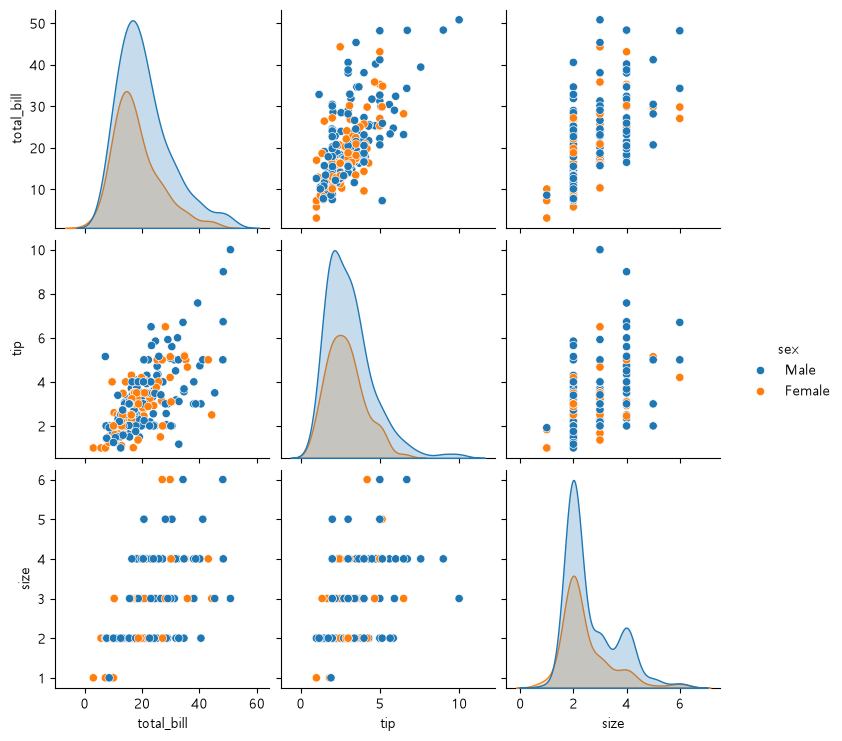

In [32]:
# 전반적인 변수간의 관계를 일괄 파악하기
sns.pairplot(tips, hue='sex')
plt.show()

판다스 그래프로 그리기


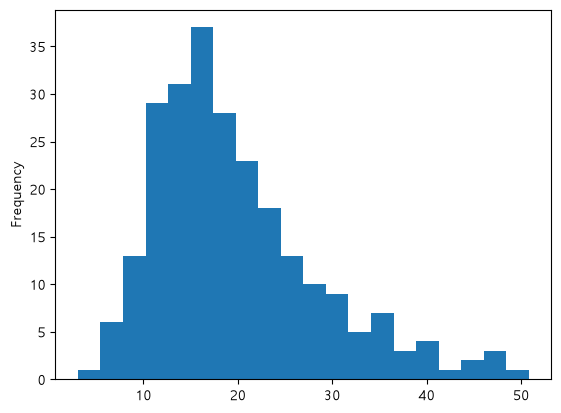

In [33]:
# 판다스로 히스토그램 그리기
tips['total_bill'].plot.hist(bins=20)
plt.show()

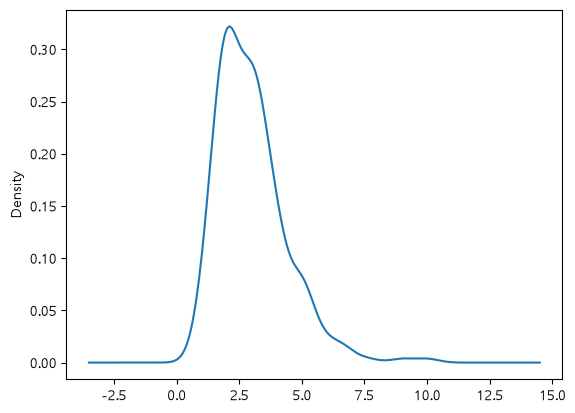

In [35]:
# 2. 판다스로 밀도 분포 그래프 그리기
plt.rcParams['axes.unicode_minus'] = False

tips['tip'].plot.kde()
plt.show()

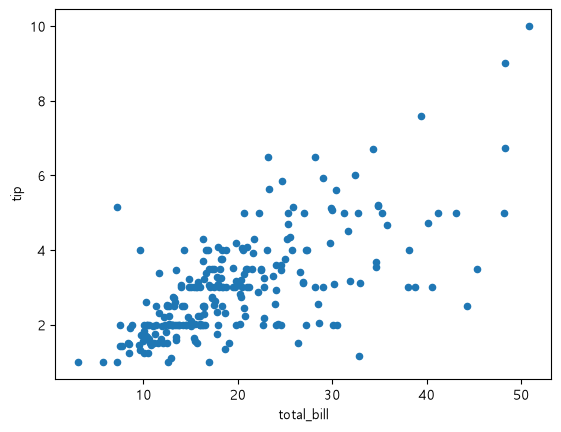

In [36]:
# 3. 판다스로 산점도 그리기
tips.plot.scatter(x='total_bill', y='tip')
plt.show()

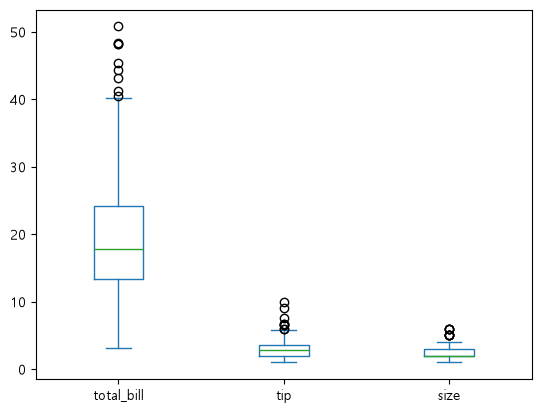

In [37]:
# 4. 판다스로 박스 플롯 그리기
tips.plot.box()
plt.show()